# 02 - POPE baseline visuals (CPU only, no model, no GPU)

Runs from the files produced by `01_colab_pope_feature_extraction.ipynb`: `pope_full_features.pt` and `pope_metadata.parquet` in `results/cached_features/`. It does **not** load the model and does **not** train probes.

**How the labels and baselines are defined (read this first).**
* `hallucination = 1` iff the model predicted *yes* and the ground truth is *no* (object absent). It is `0` for every ground-truth-*yes* row by definition.
* **False-yes rate** = P(pred yes | ground truth no). This is the hallucination rate for questions where hallucination is possible, and is the number quoted in the figures. (The mean of the `hallucination` column over all rows is half of it, because half the questions are ground-truth yes.)
* The model's answer is a forced choice between two tokens, so "is the answer yes?" is a deterministic function of the logits. Scoring *hallucination vs not* with P(yes) over absent-object questions would therefore be trivial (AUROC about 1) and would not be a baseline a probe has to beat. The **meaningful baselines** measure how well an output-level *uncertainty* signal (token probability of the chosen answer, margin, entropy) flags answers that are wrong:
  * **Task A, "hallucinated-yes detection"**: among questions where the model *answered yes*, separate the hallucinated ones (ground truth no) from the correct ones. This is the setting a user sees: "the model says yes; is it making it up?".
  * **Task B, "error detection"**: over all questions, separate wrong answers (hallucinated yes + missed yes) from correct ones.
* Margin and binary entropy are both monotone functions of |log-odds| of a two-way choice, so they give **identical** AUROC/AUPRC (they appear as tied bars). The raw token probability (not renormalised over yes/no) and the full-vocabulary entropy are the signals that can differ.

In [1]:
import os, hashlib, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score
warnings.filterwarnings("ignore", category=UserWarning)

def find_repo_root(start=None):
    p = Path(start or os.getcwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "download_datasets.py").exists():
            return q
    raise RuntimeError("Run this notebook from inside the repo")

ROOT = find_repo_root()
CACHE_DIR = Path(os.environ.get("POPE_CACHE_DIR", ROOT / "results" / "cached_features"))
FIG_DIR = Path(os.environ.get("POPE_FIG_DIR", ROOT / "results" / "figures")); FIG_DIR.mkdir(parents=True, exist_ok=True)
FEATURES_FILE, META_FILE = "pope_full_features.pt", "pope_metadata.parquet"
OLD_CACHE = ROOT / "results" / "cached_features" / "pope_subset_features.pt"
SEED, SPLIT_FRACS, N_BINS = 0, (0.70, 0.15, 0.15), 10
SETTINGS = ["random", "popular", "adversarial"]
COLORS = {"random": "#4C78A8", "popular": "#F58518", "adversarial": "#E45756", "overall": "#54A24B"}

## 1. Loader (reused later for probe training)
`load_pope_cache()` returns hidden states and metadata aligned row-for-row, and `get_split()` returns `(X, y, meta)` for a split, a layer (or all layers) and a token position. Only `"last_prompt"` exists in the cache today; an answer-token position would be a separate file (see the limitations section).

In [2]:
def _read_meta(cache_dir, meta_file=META_FILE):
    p = Path(cache_dir) / meta_file
    if p.exists():
        return pd.read_parquet(p)
    csv = p.with_suffix(".csv")
    if csv.exists():
        return pd.read_csv(csv)
    raise FileNotFoundError(f"No metadata at {p} or {csv}. Run notebook 01 on Colab and copy the outputs into {cache_dir}.")

def split_of(image_id, seed=SEED, fracs=SPLIT_FRACS):
    u = int(hashlib.md5(f"{seed}-{image_id}".encode()).hexdigest()[:8], 16) / 0xFFFFFFFF
    return "train" if u < fracs[0] else ("dev" if u < fracs[0] + fracs[1] else "test")

TOKEN_POSITION_FILES = {"last_prompt": FEATURES_FILE}      # add e.g. "first_answer": "pope_full_features_answer_token.pt" if that is ever produced

def load_pope_cache(cache_dir=CACHE_DIR, token_position="last_prompt", mmap=True):
    cache_dir = Path(cache_dir)
    path = cache_dir / TOKEN_POSITION_FILES[token_position]
    try:
        blob = torch.load(path, map_location="cpu", weights_only=True, mmap=mmap)
    except (TypeError, RuntimeError):                       # old torch without mmap
        blob = torch.load(path, map_location="cpu", weights_only=True)
    feats, row_idx = blob["features"], blob["row_idx"].numpy()
    meta = _read_meta(cache_dir)
    missing = set(row_idx.tolist()) - set(meta["row_idx"].tolist())
    if missing:
        raise ValueError(f"{len(missing)} cached feature rows have no metadata, e.g. {sorted(missing)[:5]}")
    meta = meta.set_index("row_idx", drop=False).loc[row_idx].reset_index(drop=True)   # row i of meta <-> features[i]
    if "split" not in meta.columns or meta["split"].isna().any():
        meta["split"] = [split_of(i) for i in meta["image_id"]]
    return dict(features=feats, meta=meta, token_position=token_position, path=path)

def get_split(bundle, split="train", layer=None, label="hallucination", dtype=torch.float32):
    # split in {"train","dev","test","all"}; layer=None -> [n, L, H]; layer=int (negative ok) -> [n, H]
    m = bundle["meta"]
    idx = np.arange(len(m)) if split == "all" else np.flatnonzero(m["split"].to_numpy() == split)
    X = bundle["features"][torch.as_tensor(idx)]
    if layer is not None:
        X = X[:, layer, :]
    return X.to(dtype), m[label].to_numpy()[idx], m.iloc[idx].reset_index(drop=True)

def check_loader(bundle):
    F, m = bundle["features"], bundle["meta"]
    assert F.shape[0] == len(m), "features / metadata row count differ"
    assert m["row_idx"].is_unique, "duplicate row_idx"
    assert set(m["hallucination"].unique()) <= {0, 1}
    assert m.groupby("image_id")["split"].nunique().max() == 1, "LEAKAGE: an image appears in several splits"
    for sp in ["train", "dev", "test"]:
        X, y, mm = get_split(bundle, sp, layer=-1)
        assert X.shape == (len(mm), F.shape[2]) and len(y) == len(mm)
        assert torch.isfinite(X).all()
        print(f"  {sp:5s}: X{tuple(X.shape)}  y{y.shape}  hallucination rate (all rows) {y.mean():.3f}")
    Xa, _, _ = get_split(bundle, "train", layer=None)
    print(f"  all-layer tensor for train: {tuple(Xa.shape)}  -> [n, {F.shape[1]} hidden-state entries, {F.shape[2]} hidden]")
    print("loader shape/alignment check passed")

bundle = load_pope_cache()
meta = bundle["meta"].copy()
print("features", tuple(bundle["features"].shape), bundle["features"].dtype, "| metadata", meta.shape)
check_loader(bundle)

features (9000, 29, 1536) torch.float16 | metadata (9000, 19)
  train: X(6246, 1536)  y(6246,)  hallucination rate (all rows) 0.016
  dev  : X(1440, 1536)  y(1440,)  hallucination rate (all rows) 0.023
  test : X(1314, 1536)  y(1314,)  hallucination rate (all rows) 0.021
  all-layer tensor for train: (6246, 29, 1536)  -> [n, 29 hidden-state entries, 1536 hidden]
loader shape/alignment check passed


## 2. Data QC

In [3]:
print("rows:", len(meta), "| unique images:", meta["image_id"].nunique())
print("\nper setting:\n", meta.groupby("setting").size().to_frame("n").T.to_string())
print("\nper split:\n", meta.groupby("split").size().to_frame("n").T.to_string())
print("\nsetting x split:\n", pd.crosstab(meta["setting"], meta["split"]))
print("\nground-truth yes/no per setting:\n", pd.crosstab(meta["setting"], meta["gt_answer"]))
print("\nprediction yes/no per setting:\n", pd.crosstab(meta["setting"], meta["pred_answer"]))
expected = 9000
nulls = meta[["pred_answer", "p_yes", "p_no", "p_yes_norm", "margin", "binary_entropy"]].isna().sum()
print("\nmissing/failed rows vs the 9,000-question POPE set: %d missing" % (expected - len(meta)),
      "(expected for a partial run)" if len(meta) < expected else "")
print("null values in score columns:", nulls.to_dict())
print("answer_mass (P(yes)+P(no)) mean %.3f, share below 0.9: %.3f  -> low values mean the model often does not start with Yes/No" %
      (meta["answer_mass"].mean(), (meta["answer_mass"] < 0.9).mean()))
print("most common first tokens:", meta["top1_token"].value_counts().head(5).to_dict())

rows: 9000 | unique images: 500

per setting:
 setting  adversarial  popular  random
n               3000     3000    3000

per split:
 split   dev  test  train
n      1440  1314   6246

setting x split:
 split        dev  test  train
setting                      
adversarial  480   438   2082
popular      480   438   2082
random       480   438   2082

ground-truth yes/no per setting:
 gt_answer      no   yes
setting                
adversarial  1500  1500
popular      1500  1500
random       1500  1500

prediction yes/no per setting:
 pred_answer    no   yes
setting                
adversarial  1716  1284
popular      1763  1237
random       1790  1210

missing/failed rows vs the 9,000-question POPE set: 0 missing 
null values in score columns: {'pred_answer': 0, 'p_yes': 0, 'p_no': 0, 'p_yes_norm': 0, 'margin': 0, 'binary_entropy': 0}
answer_mass (P(yes)+P(no)) mean 0.997, share below 0.9: 0.000  -> low values mean the model often does not start with Yes/No
most common first tokens:

## 3. Train / dev / test handling
Split by **image** (hash of `image_id` and seed), assigned in notebook 01. There are only 500 images and **every image appears in all three POPE settings**, so splitting rows within a setting, or splitting by setting, would put the same image's questions on both sides of train/test (leakage). The image-level split below avoids that. Limitations: with 500 images the dev/test sets hold only ~75 images (~1,350 questions) each, so per-setting numbers on those splits are noisy; and the split is by image, not by object category, so the same object words recur across splits (benign here, but a probe could learn object priors).

In [4]:
leak = meta.groupby("image_id")["split"].nunique()
print("images appearing in >1 split:", int((leak > 1).sum()), "-> no leakage" if (leak <= 1).all() else "-> LEAKAGE")
print("images per split:", meta.groupby("split")["image_id"].nunique().to_dict())
recomputed = np.array([split_of(i) for i in meta["image_id"]])
print("split column matches the hash rule seeded with", SEED, ":", bool((recomputed == meta["split"].to_numpy()).all()))

images appearing in >1 split: 0 -> no leakage
images per split: {'dev': 80, 'test': 73, 'train': 347}
split column matches the hash rule seeded with 0 : True


## 4. Derived columns and metric helpers

In [5]:
meta["gt_yes"] = (meta["gt_answer"] == "yes").astype(int)
meta["pred_yes"] = (meta["pred_answer"] == "yes").astype(int)
meta["correct"] = (meta["pred_answer"] == meta["gt_answer"]).astype(int)
meta["error"] = 1 - meta["correct"]
meta["conf"] = np.maximum(meta["p_yes_norm"], 1 - meta["p_yes_norm"])            # confidence of the chosen answer, renormalised over yes/no
meta["raw_conf"] = np.where(meta["pred_yes"] == 1, meta["p_yes"], meta["p_no"])  # raw token probability of the chosen answer
meta["outcome"] = np.select(
    [(meta.pred_yes == 1) & (meta.gt_yes == 1), (meta.pred_yes == 0) & (meta.gt_yes == 0),
     (meta.pred_yes == 1) & (meta.gt_yes == 0), (meta.pred_yes == 0) & (meta.gt_yes == 1)],
    ["correct yes", "correct no", "hallucinated yes", "missed yes"], default="other")

# uncertainty scores: HIGHER = more likely to be a bad answer
UNC = {
    "token prob (raw)": 1 - meta["raw_conf"],
    "margin (|log-odds|)": -meta["margin"].abs(),
    "binary entropy": meta["binary_entropy"],
    "vocab entropy": meta["vocab_entropy"],
}

def ece_score(conf, correct, n_bins=N_BINS):
    conf, correct = np.asarray(conf), np.asarray(correct)
    bins = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    e = 0.0
    for b in range(n_bins):
        mk = bins == b
        if mk.any():
            e += mk.mean() * abs(correct[mk].mean() - conf[mk].mean())
    return e

def safe(fn, y, s):
    return fn(y, s) if len(np.unique(y)) == 2 else np.nan

def disc_table(mask_fn, label_col, settings=SETTINGS):
    rows = []
    for st in ["overall"] + settings:
        sel = np.ones(len(meta), bool) if st == "overall" else (meta["setting"] == st).to_numpy()
        sel = sel & np.asarray(mask_fn(meta))
        y = meta.loc[sel, label_col].to_numpy()
        for name, s in UNC.items():
            rows.append(dict(setting=st, signal=name, n=int(sel.sum()), n_pos=int(y.sum()), prevalence=y.mean() if len(y) else np.nan,
                             auroc=safe(roc_auc_score, y, s[sel]), auprc=safe(average_precision_score, y, s[sel])))
    return pd.DataFrame(rows)

## 5. Figures

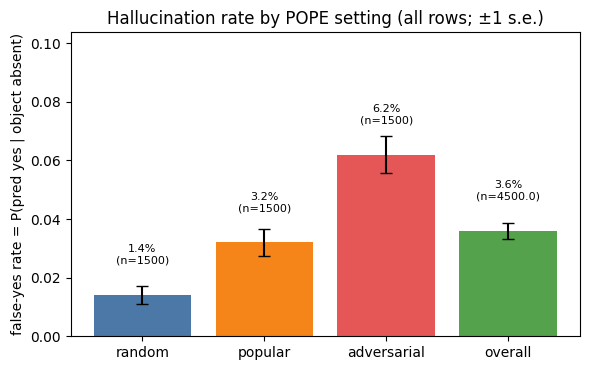

In [6]:
# Fig 1: hallucination (false-yes) rate by setting
absent = meta[meta.gt_yes == 0]
g = absent.groupby("setting")["pred_yes"].agg(["mean", "size"]).reindex(SETTINGS)
ov = absent["pred_yes"].agg(["mean", "size"])
vals = list(g["mean"]) + [ov["mean"]]; ns = list(g["size"]) + [ov["size"]]; labs = SETTINGS + ["overall"]
se = [np.sqrt(v * (1 - v) / n) for v, n in zip(vals, ns)]
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.bar(labs, vals, yerr=se, color=[COLORS[l] for l in labs], capsize=4)
for i, (v, n) in enumerate(zip(vals, ns)):
    ax.text(i, v + 0.01, f"{v:.1%}\n(n={n})", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("false-yes rate = P(pred yes | object absent)"); ax.set_ylim(0, max(vals) * 1.35 + 0.02)
ax.set_title("Hallucination rate by POPE setting (all rows; ±1 s.e.)")
fig.tight_layout(); fig.savefig(FIG_DIR / "pope_false_yes_rate_by_setting.png", dpi=150); plt.show()

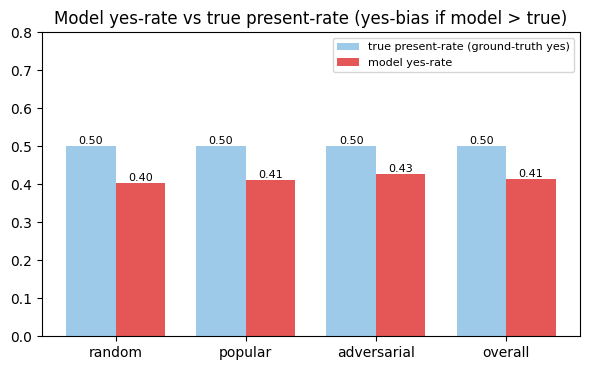

In [7]:
# Fig 2: model yes-rate vs true present-rate
yr = meta.groupby("setting")[["pred_yes", "gt_yes"]].mean().reindex(SETTINGS)
yr.loc["overall"] = meta[["pred_yes", "gt_yes"]].mean()
x = np.arange(len(yr)); w = 0.38
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.bar(x - w / 2, yr["gt_yes"], w, label="true present-rate (ground-truth yes)", color="#9ecae9")
ax.bar(x + w / 2, yr["pred_yes"], w, label="model yes-rate", color="#E45756")
for xi, (a, b) in enumerate(zip(yr["gt_yes"], yr["pred_yes"])):
    ax.text(xi - w / 2, a + 0.005, f"{a:.2f}", ha="center", fontsize=8); ax.text(xi + w / 2, b + 0.005, f"{b:.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(yr.index); ax.set_ylim(0, 0.8); ax.legend(fontsize=8)
ax.set_title("Model yes-rate vs true present-rate (yes-bias if model > true)")
fig.tight_layout(); fig.savefig(FIG_DIR / "pope_yes_rate_vs_true_present_rate.png", dpi=150); plt.show()

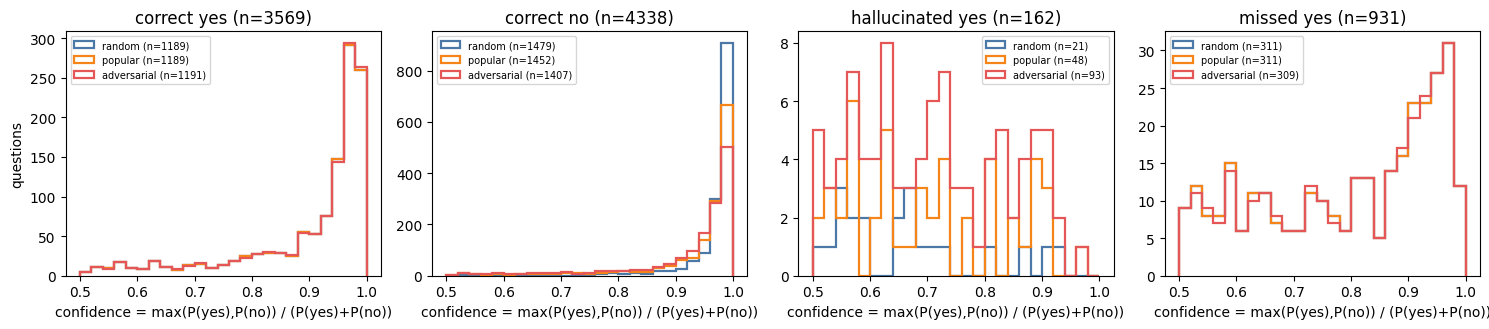

In [8]:
# Fig 3: confidence histograms by outcome
outcomes = ["correct yes", "correct no", "hallucinated yes", "missed yes"]
bins = np.linspace(0.5, 1.0, 26)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=False)
for ax, oc in zip(axes, outcomes):
    sub = meta[meta.outcome == oc]
    for st in SETTINGS:
        v = sub.loc[sub.setting == st, "conf"]
        if len(v):
            ax.hist(v, bins=bins, histtype="step", lw=1.6, color=COLORS[st], label=f"{st} (n={len(v)})")
    ax.set_title(f"{oc} (n={len(sub)})"); ax.set_xlabel("confidence = max(P(yes),P(no)) / (P(yes)+P(no))"); ax.legend(fontsize=7)
axes[0].set_ylabel("questions")
fig.tight_layout(); fig.savefig(FIG_DIR / "pope_confidence_hist_by_outcome.png", dpi=150); plt.show()

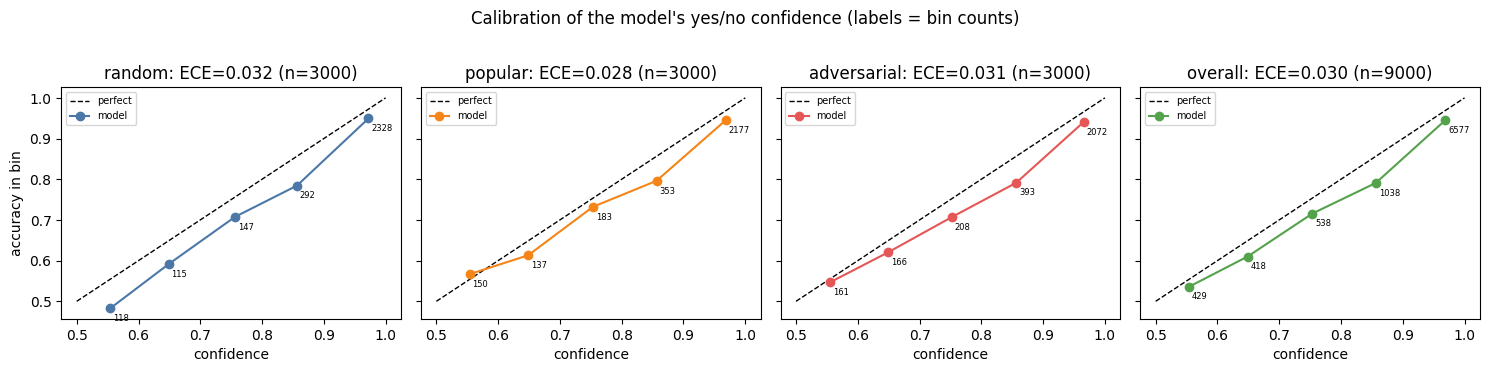

In [9]:
# Fig 4: calibration curves per setting + ECE
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
ece_by = {}
for ax, st in zip(axes, SETTINGS + ["overall"]):
    d = meta if st == "overall" else meta[meta.setting == st]
    b = np.minimum((d["conf"].to_numpy() * N_BINS).astype(int), N_BINS - 1)
    xs, ys, cnt = [], [], []
    for k in range(N_BINS):
        mk = b == k
        if mk.sum() >= 5:
            xs.append(d["conf"].to_numpy()[mk].mean()); ys.append(d["correct"].to_numpy()[mk].mean()); cnt.append(mk.sum())
    ece_by[st] = ece_score(d["conf"], d["correct"])
    ax.plot([0.5, 1], [0.5, 1], "k--", lw=1, label="perfect")
    ax.plot(xs, ys, marker="o", color=COLORS[st], label="model")
    for xv, yv, c in zip(xs, ys, cnt):
        ax.annotate(str(c), (xv, yv), fontsize=6, xytext=(2, -9), textcoords="offset points")
    ax.set_title(f"{st}: ECE={ece_by[st]:.3f} (n={len(d)})"); ax.set_xlabel("confidence"); ax.legend(fontsize=7)
axes[0].set_ylabel("accuracy in bin")
fig.suptitle("Calibration of the model's yes/no confidence (labels = bin counts)", y=1.02)
fig.tight_layout(); fig.savefig(FIG_DIR / "pope_calibration_by_setting.png", dpi=150, bbox_inches="tight"); plt.show()

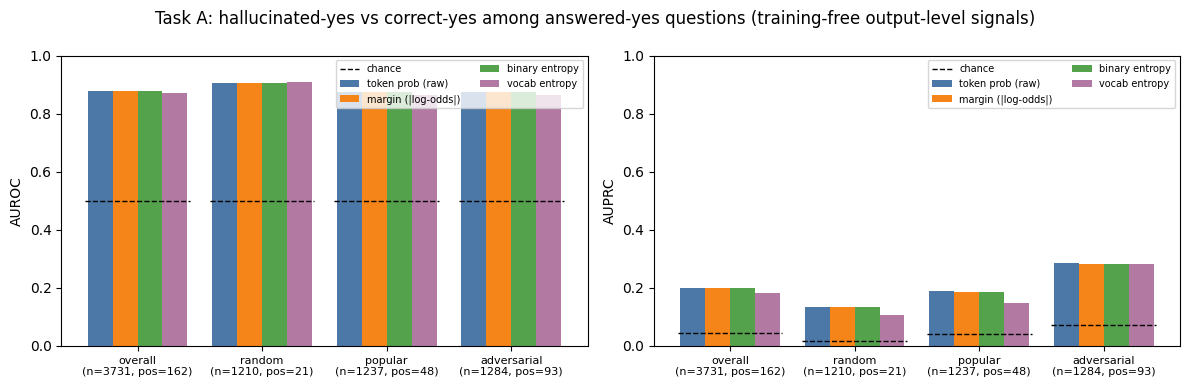

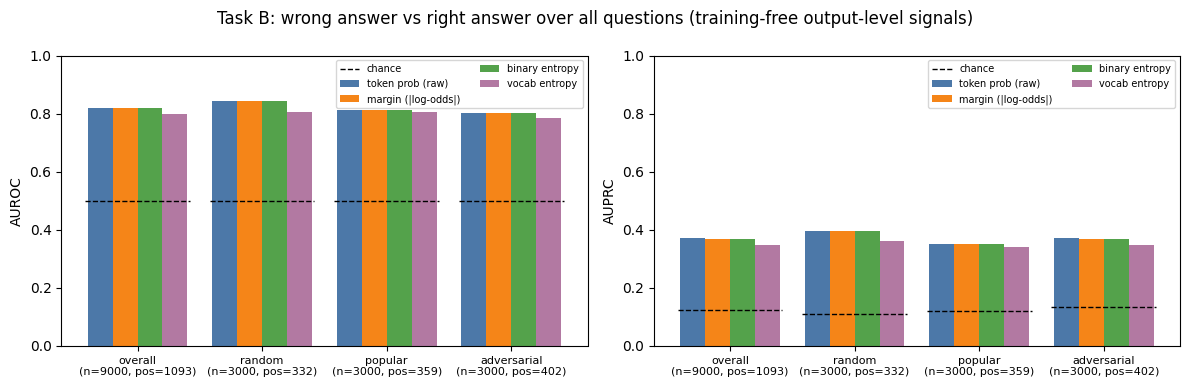

In [10]:
# Fig 5: baseline discrimination (AUROC / AUPRC) - the bars a probe must beat
taskA = disc_table(lambda d: (d.pred_yes == 1).to_numpy(), "hallucination")          # among answered-yes: hallucinated vs correct yes
taskB = disc_table(lambda d: np.ones(len(d), bool), "error")                           # all rows: wrong vs right
sig_colors = dict(zip(UNC.keys(), ["#4C78A8", "#F58518", "#54A24B", "#B279A2"]))
def bar_fig(tab, title, fname):
    groups = ["overall"] + SETTINGS
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
    for ax, metric in zip(axes, ["auroc", "auprc"]):
        w = 0.2
        for i, sname in enumerate(UNC):
            v = [tab[(tab.setting == gname) & (tab.signal == sname)][metric].iloc[0] for gname in groups]
            ax.bar(np.arange(len(groups)) + (i - 1.5) * w, v, w, label=sname, color=sig_colors[sname])
        prev = [tab[(tab.setting == gname)]["prevalence"].iloc[0] for gname in groups]
        ref = [0.5] * len(groups) if metric == "auroc" else prev
        for xi, r in enumerate(ref):
            ax.hlines(r, xi - 0.42, xi + 0.42, color="k", ls="--", lw=1, label="chance" if xi == 0 else None)
        ax.set_xticks(range(len(groups))); ax.set_xticklabels([f"{gname}\n(n={tab[tab.setting == gname]['n'].iloc[0]}, pos={tab[tab.setting == gname]['n_pos'].iloc[0]})" for gname in groups], fontsize=8)
        ax.set_ylabel(metric.upper()); ax.set_ylim(0, 1.0); ax.legend(fontsize=7, ncol=2)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(FIG_DIR / fname, dpi=150); plt.show()
bar_fig(taskA, "Task A: hallucinated-yes vs correct-yes among answered-yes questions (training-free output-level signals)", "pope_baseline_discrimination_taskA_hallucinated_yes.png")
bar_fig(taskB, "Task B: wrong answer vs right answer over all questions (training-free output-level signals)", "pope_baseline_discrimination_taskB_error.png")

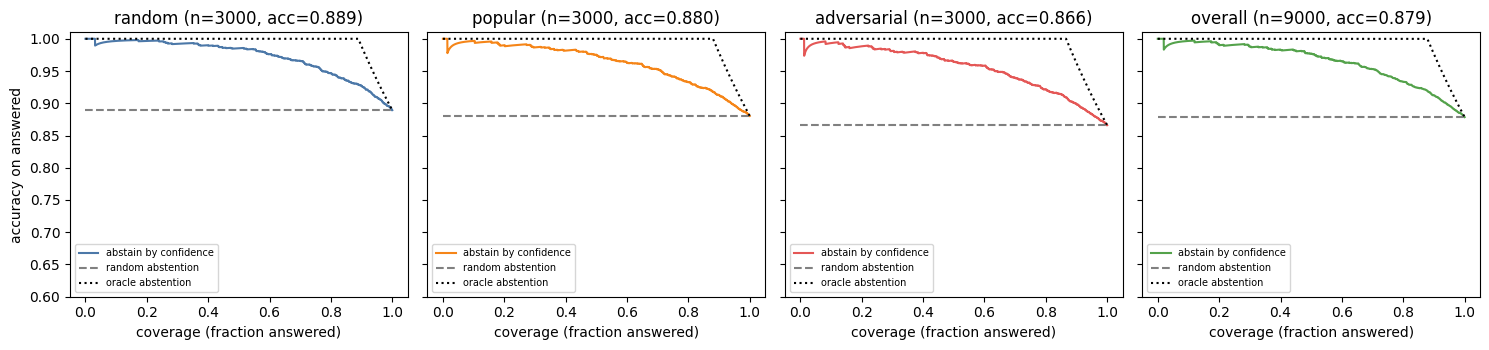

In [11]:
# Fig 6: accuracy-coverage curves
def acc_cov(conf, correct):
    o = np.argsort(-np.asarray(conf), kind="stable")
    c = np.asarray(correct)[o]
    k = np.arange(1, len(c) + 1)
    return k / len(c), np.cumsum(c) / k
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
aucc = {}
for ax, st in zip(axes, SETTINGS + ["overall"]):
    d = meta if st == "overall" else meta[meta.setting == st]
    cov, acc = acc_cov(d["conf"], d["correct"])
    base = d["correct"].mean()
    oracle = np.where(cov <= base, 1.0, base / cov)
    ax.plot(cov, acc, color=COLORS[st], label="abstain by confidence")
    ax.hlines(base, 0, 1, color="gray", ls="--", label="random abstention")
    ax.plot(cov, oracle, color="k", ls=":", label="oracle abstention")
    aucc[st] = dict(area=np.trapezoid(acc, cov) if hasattr(np, "trapezoid") else np.trapz(acc, cov), oracle_area=np.trapezoid(oracle, cov) if hasattr(np, "trapezoid") else np.trapz(oracle, cov))
    ax.set_title(f"{st} (n={len(d)}, acc={base:.3f})"); ax.set_xlabel("coverage (fraction answered)"); ax.legend(fontsize=7, loc="lower left")
axes[0].set_ylabel("accuracy on answered"); axes[0].set_ylim(min(0.6, meta["correct"].mean() - 0.05), 1.01)
fig.tight_layout(); fig.savefig(FIG_DIR / "pope_accuracy_coverage.png", dpi=150); plt.show()

## 6. Results table (quotable)
Training-free signals need no fitting, so the table is computed on **all rows** and again on the **test split only** (the split a probe will be judged on).

In [12]:
def results_table(d_all, tag):
    out = []
    for st in ["overall"] + SETTINGS:
        d = d_all if st == "overall" else d_all[d_all.setting == st]
        ab = d[d.gt_yes == 0]
        row = dict(subset=tag, setting=st, n=len(d), accuracy=d["correct"].mean(), yes_rate=d["pred_yes"].mean(), true_present_rate=d["gt_yes"].mean(),
                   false_yes_rate=ab["pred_yes"].mean(), hallucination_mean_all_rows=d["hallucination"].mean(), missed_yes_rate=1 - d[d.gt_yes == 1]["pred_yes"].mean(),
                   ECE=ece_score(d["conf"], d["correct"]))
        for task, mask, lab in [("A", d.pred_yes == 1, "hallucination"), ("B", np.ones(len(d), bool), "error")]:
            dd = d[mask]
            for name, s in UNC.items():
                s_ = s.loc[dd.index]
                row[f"{task}_AUROC_{name}"] = safe(roc_auc_score, dd[lab], s_)
                row[f"{task}_AUPRC_{name}"] = safe(average_precision_score, dd[lab], s_)
            row[f"{task}_n"] = len(dd); row[f"{task}_pos_rate"] = dd[lab].mean() if len(dd) else np.nan
        out.append(row)
    return pd.DataFrame(out)

table = pd.concat([results_table(meta, "all"), results_table(meta[meta.split == "test"], "test")], ignore_index=True)
table.to_csv(FIG_DIR / "pope_baseline_results_table.csv", index=False)
pd.set_option("display.width", 250, "display.max_columns", 60)
print("Task A = hallucinated-yes among answered-yes questions; Task B = any wrong answer.  Higher AUROC/AUPRC = better.")
display(table[["subset", "setting", "n", "accuracy", "yes_rate", "true_present_rate", "false_yes_rate", "missed_yes_rate", "ECE"]].round(4))
display(table[["subset", "setting"] + [c for c in table.columns if c.startswith("A_")]].round(4))
display(table[["subset", "setting"] + [c for c in table.columns if c.startswith("B_")]].round(4))
print("saved", FIG_DIR / "pope_baseline_results_table.csv")

Task A = hallucinated-yes among answered-yes questions; Task B = any wrong answer.  Higher AUROC/AUPRC = better.


,subset,setting,n,accuracy,yes_rate,true_present_rate,false_yes_rate,missed_yes_rate,ECE
0,all,overall,9000,0.8786,0.4146,0.5,0.0360,0.2069,0.0298
1,all,random,3000,0.8893,0.4033,0.5,0.0140,0.2073,0.0322
2,all,popular,3000,0.8803,0.4123,0.5,0.0320,0.2073,0.0276
3,all,adversarial,3000,0.8660,0.4280,0.5,0.0620,0.2060,0.0310
4,test,overall,1314,0.8737,0.4163,0.5,0.0426,0.2100,0.0393
5,test,random,438,0.8858,0.4041,0.5,0.0183,0.2100,0.0388
6,test,popular,438,0.8767,0.4132,0.5,0.0365,0.2100,0.0373
7,test,adversarial,438,0.8584,0.4315,0.5,0.0731,0.2100,0.0418


,subset,setting,A_AUROC_token prob (raw),A_AUPRC_token prob (raw),A_AUROC_margin (|log-odds|),A_AUPRC_margin (|log-odds|),A_AUROC_binary entropy,A_AUPRC_binary entropy,A_AUROC_vocab entropy,A_AUPRC_vocab entropy,A_n,A_pos_rate
0,all,overall,0.8784,0.1994,0.8786,0.1982,0.8786,0.1982,0.8705,0.1812,3731,0.0434
1,all,random,0.9044,0.1316,0.9048,0.1347,0.9048,0.1347,0.9103,0.1046,1210,0.0174
2,all,popular,0.8733,0.1886,0.8735,0.1859,0.8735,0.1859,0.8652,0.1485,1237,0.0388
3,all,adversarial,0.8753,0.2847,0.8755,0.2832,0.8755,0.2832,0.8644,0.2818,1284,0.0724
4,test,overall,0.8437,0.2179,0.8435,0.2210,0.8435,0.2210,0.8107,0.1490,547,0.0512
5,test,random,0.8006,0.0930,0.8020,0.0931,0.8020,0.0931,0.8208,0.0984,177,0.0226
6,test,popular,0.8555,0.2144,0.8548,0.2308,0.8548,0.2308,0.7861,0.1222,181,0.0442
7,test,adversarial,0.8493,0.3280,0.8490,0.3260,0.8490,0.3260,0.8230,0.2596,189,0.0847


,subset,setting,B_AUROC_token prob (raw),B_AUPRC_token prob (raw),B_AUROC_margin (|log-odds|),B_AUPRC_margin (|log-odds|),B_AUROC_binary entropy,B_AUPRC_binary entropy,B_AUROC_vocab entropy,B_AUPRC_vocab entropy,B_n,B_pos_rate
0,all,overall,0.8195,0.3702,0.8187,0.3688,0.8187,0.3687,0.7994,0.3479,9000,0.1214
1,all,random,0.8446,0.3969,0.8440,0.3960,0.8440,0.3960,0.8054,0.3597,3000,0.1107
2,all,popular,0.8121,0.3505,0.8110,0.3502,0.8110,0.3499,0.8052,0.3412,3000,0.1197
3,all,adversarial,0.8015,0.3702,0.8008,0.3673,0.8008,0.3671,0.7859,0.3467,3000,0.1340
4,test,overall,0.8091,0.3803,0.8078,0.3788,0.8078,0.3788,0.8012,0.3384,1314,0.1263
5,test,random,0.8310,0.4039,0.8306,0.4018,0.8306,0.4018,0.8125,0.3658,438,0.1142
6,test,popular,0.8043,0.3671,0.8022,0.3664,0.8022,0.3664,0.8033,0.3261,438,0.1233
7,test,adversarial,0.7911,0.3790,0.7896,0.3775,0.7896,0.3775,0.7857,0.3369,438,0.1416


saved C:\Users\Low Jun Keat\SC4001\results\figures\pope_baseline_results_table.csv


## 7. Optional: settle the question about the old 100-sample cache
If `pope_subset_features.pt` was made from rows 0..99 with the same model and prompt, its tensors should closely match the new cache's rows 0..99 (same position, all layers), up to float16-vs-bfloat16 noise. This is the only way to verify the alignment that notebook 00 could not.

In [13]:
if OLD_CACHE.exists() and (meta["row_idx"] < 100).sum() == 100:
    old = torch.stack(torch.load(OLD_CACHE, map_location="cpu")).float()               # [100, L, H]
    pos = {r: i for i, r in enumerate(meta["row_idx"])}
    new = bundle["features"][torch.tensor([pos[r] for r in range(100)])].float()
    if old.shape == new.shape:
        cos = torch.nn.functional.cosine_similarity(old, new, dim=-1)                  # [100, L]
        print("per-layer mean cosine(old[i], new[i]) for rows 0..99:", cos.mean(0).numpy().round(3).tolist())
        shuffled = torch.nn.functional.cosine_similarity(old, new.roll(1, 0), dim=-1)
        print("same but mismatched pairing (row i vs i-1), for reference:", shuffled.mean(0).numpy().round(3).tolist()[-5:])
        print("-> aligned if the matched cosine is ~0.99+ and clearly above the mismatched reference in the middle/late layers.")
    else:
        print("shape mismatch", tuple(old.shape), tuple(new.shape))
else:
    print("Skipped (old cache missing, or rows 0..99 not all present in the new run, e.g. SUBSET_SIZE/POPE_SETTINGS changed).")

Skipped (old cache missing, or rows 0..99 not all present in the new run, e.g. SUBSET_SIZE/POPE_SETTINGS changed).


## 8. Limitations and next steps

**What this cache supports for probe training**
* One hidden-state vector per question (last prompt token = the position that predicts the first answer token), for every layer (29 entries for Qwen2-VL-2B: embeddings + 28 layers; sizes are read from the file), in float16, with row-aligned labels, model predictions, logit-based scores and image-level train/dev/test splits. Layer sweeps and a train/dev/test probe comparison against the baselines above can be done without touching the model.
* Label caveat: at this position the hidden state determines the yes/no logits, so a probe for "predicted yes" would be trivial. The meaningful probe targets are Task A / Task B above (is this answer a hallucination / an error), possibly restricted to answered-yes or ground-truth-no questions, and compared with the AUROC/AUPRC bars here.
* Only ~4,500 ground-truth-no questions exist in total and the hallucinated-yes class may be small (especially in the `random` setting), so expect noisy per-setting numbers; use dev for layer selection and touch test once.

**What it does not support**
* No hidden states at later positions (first generated token, or mean over image tokens). Those would need another Colab run into a **separate** file (roughly doubling storage per extra position).
* No free-form generation, so no self-consistency across sampled answers and no verbalised-confidence baseline (both are optional future baselines, not implemented).
* **AMBER transfer is not possible from this cache**: it needs the same extraction run on AMBER with the same model, prompt and token position (and AMBER has its own question types, so label definitions must be re-checked).
* The old `pope_subset_features.pt` is exploratory only unless section 7 confirms alignment; it is float16 from a different code version of the pipeline and covers only the first 100 (adversarial) rows.
* 500 images in total; every image appears in all three settings, so the settings are not independent samples.